In [1]:
import numpy as np, matplotlib.pyplot as plt
import scipy.integrate as scint
from scipy.integrate import solve_ivp
trapz = getattr(np, "trapezoid", None) or np.trapz   # np.trapz is np.trapezoid in NumPy 2

## 1. `trapz` vs `quad`
$\int_0^{10} x^2\,dx = 1000/3$

In [2]:
x = np.linspace(0, 10, 11)
print("trapz:", trapz(x**2, x))                      # depends on number of points
print("quad :", scint.quad(lambda x: x**2, 0, 10))   # (value, abserr)
print("inf bound example  :", scint.quad(lambda x: np.exp(-x**2), -np.inf, np.inf)[0], np.sqrt(np.pi))

trapz: 335.0
quad : (333.33333333333337, 3.700743415417189e-12)
inf bound example  : 1.7724538509055159 1.7724538509055159


## 2. Activity: `quad` signature and example
Integrate $a x^2$ from 0 to 10 with $a=3$.

In [3]:
#help(scint.quad)
def f(x, a):
    return a * x**2

value, abserr = scint.quad(f, 0, 10, args=(3,))
print(value, abserr)   # 1000

1000.0000000000001 1.1102230246251567e-11


## 3. Euler's method
$y_{n+1} = y_n + \tau f(t_n, y_n)$ for $dy/dt=-2y$, $y(0)=1$

[1.    0.5   0.25  0.125]


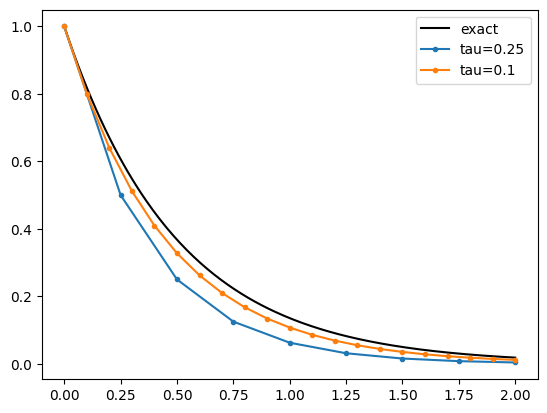

In [4]:
def f(t, y):            # always f(t, y), even if t is unused
    return -2*y

def euler(f, y0, tf, tau):
    t = np.arange(0, tf + tau/2, tau); y = np.zeros(len(t)); y[0] = y0
    for n in range(len(t) - 1):
        y[n+1] = y[n] + tau * f(t[n], y[n])
    return t, y

print(euler(f, 1.0, 0.75, 0.25)[1])   # Slide 7: 1, 0.5, 0.25, 0.125

tt = np.linspace(0, 2, 200); plt.plot(tt, np.exp(-2*tt), "k", label="exact")
for tau in [0.25, 0.1]:
    plt.plot(*euler(f, 1.0, 2, tau), "o-", ms=3, label=f"tau={tau}")
plt.legend(); plt.show()

## 6. `solve_ivp`: harmonic oscillator example
$dx/dt=v$, $dv/dt=-kx$, $k=1$, $x(0)=1$, $v(0)=0$

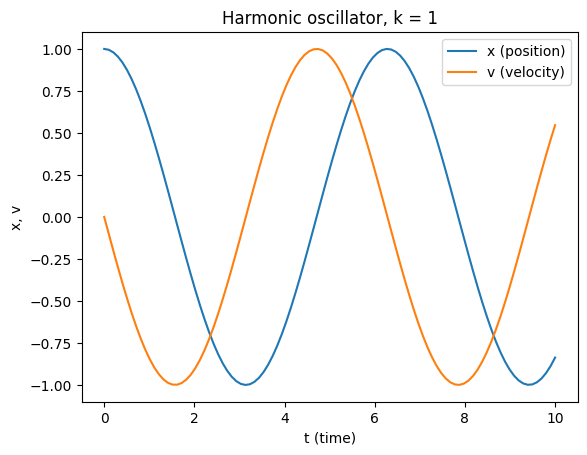

In [13]:
# help(solve_ivp)
def ode_function(t, ystate, k):
    x, v = ystate                # same order as ystate0
    dxdt = v
    dvdt = -k*x
    return [dxdt, dvdt]

ystate0 = [1.0, 0.0]             # [x0, v0]
t_span = (0, 10)
t_eval = np.linspace(*t_span, 100)
sol = solve_ivp(ode_function, t_span, ystate0, t_eval=t_eval, args=(1,))


#x = sol.y[0]
#v = sol.y[1]

plt.plot(sol.t, x, label="x (position)")
plt.plot(sol.t, v, label="v (velocity)")
plt.xlabel("t (time)")
plt.ylabel("x, v")
plt.title("Harmonic oscillator, k = 1")
plt.legend(); plt.show()
